# Fase B — Limpieza y Normalización de Datos
**Dataset:** Siniestros Viales — Cali 2016–2024 (el mismo del Proyecto 1) · **Grupo #5** · **Objetivo del pipeline:** dejar una tabla lista para modelar la gravedad del siniestro, tanto en versión binaria `es_grave` (1 = con lesionado o fallecido, 0 = solo daños) como con los tres niveles definidos en el Proyecto 1, `gravedad_p1` (*leve / grave / mortal*).

**Continuidad con el P1:** este notebook cumple el papel del ETL previsto en el Proyecto 1. Aplica las reglas definidas allí (registro por defecto *"Desconocido"* para los faltantes, regla de desduplicación por `id_siniestro`) y resuelve las validaciones pendientes de su sección 7 (ver 1.4).

**Pipeline (en orden):**
1. Carga y diagnóstico: nulos (incluidos los "disfrazados" con `.`), duplicados, inconsistencias de texto y outliers
2. Selección de alcance y eliminación de columnas redundantes o con fuga de información (*data leakage*)
3. Estandarización de texto (mayúsculas, tildes, caracteres corruptos, sinónimos)
4. Ingeniería de variables (calendario, familias de vehículos, dirección)
5. **Partición train/test (80/20) antes de imputar y escalar**, para que ningún estadístico vea el conjunto de prueba
6. Imputación de nulos con 3 estrategias + categoría explícita, ajustadas solo con *train*
7. Tratamiento de outliers (Z-score e IQR)
8. Transformación logarítmica / Yeo-Johnson de variables sesgadas
9. Codificación: Ordinal Encoding y One-Hot Encoding (`pd.get_dummies(drop_first=True)`)
10. Escalado: Min-Max, Z-score y RobustScaler (ajustados en *train*)
11. Guardado en `datos_limpios.parquet`

In [1]:
# Librerías
import os
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import (OrdinalEncoder, MinMaxScaler, StandardScaler,
                                   RobustScaler, PowerTransformer)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold"})
RUTA_DATOS = Path(os.getenv("DATA_PATH", "../datos/siniestralidad_2016_2024.csv"))
RUTA_FIG = Path("figuras"); RUTA_FIG.mkdir(exist_ok=True)
SEMILLA = int(os.getenv("RANDOM_STATE", 42))

## 1. Carga y diagnóstico

In [2]:
# Carga como texto y nombres cortos de columna
df = pd.read_csv(RUTA_DATOS, sep=";", encoding="cp1252", dtype=str)
df.columns = ["codigo", "fecha", "tipo_confirmado", "direccion", "clase_accidente",
              "clase_accidente_dup", "detalle_confirmado", "medio_reporte",
              "num_vehiculos", "vehiculos_implicados"]
print("Filas y columnas originales:", df.shape)

Filas y columnas originales: (371003, 10)


In [3]:
# 1.1 Nulos: NaN explícito + '.' y cadenas vacías usadas como "sin dato"
def diagnostico_nulos(d):
    """Tabla con nulos explícitos, nulos disfrazados ('.' o vacío) y % total por columna."""
    disfrazados = d.apply(lambda s: s.astype(str).str.strip().isin([".", ""]).sum())
    t = pd.DataFrame({"NaN": d.isna().sum(), "punto_o_vacio": disfrazados})
    t["%_total"] = ((t.NaN + t.punto_o_vacio) / len(d) * 100).round(2)
    return t.sort_values("%_total", ascending=False)
diagnostico_nulos(df)

,NaN,punto_o_vacio,%_total
clase_accidente,1,325257,87.67
clase_accidente_dup,1,325257,87.67
medio_reporte,0,288099,77.65
vehiculos_implicados,0,222214,59.90
num_vehiculos,0,194424,52.40
direccion,181593,2093,49.51
detalle_confirmado,0,23389,6.30
codigo,1,0,0.00
fecha,1,0,0.00
tipo_confirmado,1,2,0.00


In [4]:
# 1.2 Duplicados: filas idénticas y códigos repetidos
print("Filas completamente duplicadas:", df.duplicated().sum())
print("Códigos repetidos:", df["codigo"].duplicated().sum())
print("Fila sin código ni fecha:", df["codigo"].isna().sum())
df[df["codigo"].duplicated(keep=False)].sort_values("codigo")

Filas completamente duplicadas: 4
Códigos repetidos: 4
Fila sin código ni fecha: 1


,codigo,fecha,tipo_confirmado,direccion,clase_accidente,clase_accidente_dup,detalle_confirmado,medio_reporte,num_vehiculos,vehiculos_implicados
254426,350723,27/02/2020,Solo daños,NaN,.,.,Arreglo Formal,.,2,"AUTOMOVIL,AUTOMOVIL"
254427,350723,27/02/2020,Solo daños,NaN,.,.,Arreglo Formal,.,2,"AUTOMOVIL,AUTOMOVIL"
258142,354438,5/04/2020,Negativo,NaN,.,.,Negativo,.,2,.
258143,354438,5/04/2020,Negativo,NaN,.,.,Negativo,.,2,.
264668,361442,8/08/2020,Negativo,NaN,.,.,Negativo,.,.,.
264669,361442,8/08/2020,Negativo,NaN,.,.,Negativo,.,.,.
264701,361474,8/08/2020,Negativo,NaN,.,.,Negativo,.,.,.
264702,361474,8/08/2020,Negativo,NaN,.,.,Negativo,.,.,.


In [5]:
# 1.3 Inconsistencias de texto: mismas categorías escritas de varias formas
for col in ["tipo_confirmado", "clase_accidente", "medio_reporte", "num_vehiculos"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().head(16).to_string())


--- tipo_confirmado ---
tipo_confirmado
Negativo                   246110
Solo daños                  73828
Con lesionado               47500
Con fallecido                2907
Con fallecido (Foraneo)       453
Solo Daños                    202
.                               2

--- clase_accidente ---
clase_accidente
.                    325257
Choque                20548
CHOQUE                12084
ATROPELLO              5618
NO APLICA              2819
VOLCAMIENTO            1350
CAIDA DE OCUPANTE      1105
Atropello               993
Volcamiento             588
Ca?da Ocupante          371
OTRO                    118
Otro                     82
NOAPLICA                 66
Da?os                     2
Incendio                  1

--- medio_reporte ---
medio_reporte
.                                                                                                                                                                                                                              

**Diagnóstico:**
- **Nulos disfrazados:** la base usa `.` como vacío. `clase_accidente` (88 %) y `medio_reporte` (78 %) están casi vacías y `direccion` falta en ~50 %.
- **Duplicados:** 4 filas idénticas (códigos 350723, 354438, 361442, 361474) y 1 fila totalmente vacía al final.
- **Texto inconsistente:** `CHOQUE` / `Choque`, `NO APLICA` / `NOAPLICA`, `Solo daños` / `Solo Daños`, `TELEF?NICO 127` / `TELEF?NICO127`, y caracteres corruptos (`Ca?da`, `TELEF?NICO`) por la codificación del archivo. `medio_reporte` contiene además dos textos libres que son observaciones mal ubicadas, y `num_vehiculos` tiene el valor `1.`.
- **Columnas redundantes:** `clase_accidente_dup` es idéntica a `clase_accidente` en el 99,9997 % de las filas.

### 1.4 Validaciones pendientes del Proyecto 1 (sección 7 del diseño de la bodega)
| Validación pendiente en el P1 | Resultado con el CSV real | Decisión |
|---|---|---|
| Confirmar nombres de columnas, codificación y nulos | 10 columnas, 2 repetidas en el encabezado; codificación **cp1252**, separador `;`; nulos escritos como `.` | Lectura con `encoding="cp1252"`, renombrado a nombres cortos y `.` → nulo |
| ¿Existe un campo de hora / franja horaria? | **No**: solo fecha (día/mes/año) | `DIM_TIEMPO` queda en grano diario; el objetivo "comuna-hora" se reemplaza por día de la semana y mes |
| ¿Existen `clase_via`, `superficie` y `zona`? | **No**. Tampoco comuna, barrio, género ni edad | Se documentan como *No disponible*; `tipo_via` se extrae de la dirección |
| Regla para faltantes en dimensiones (`-1 / Desconocido`) | Faltantes estructurales en clase de accidente (78 %), medio de reporte (78 %) y dirección (56 %) | Misma lógica del P1 en la tabla analítica: categoría explícita `SIN_DATO` + indicadores de faltante |
| Duplicados de `id_siniestro` y regla de desduplicación | 4 códigos repetidos, todos duplicados exactos (1 de ellos en siniestros confirmados) | Se conserva una sola fila por código (`drop_duplicates`) |

## 2. Alcance y columnas que se eliminan
- Se eliminan duplicados exactos y la fila vacía.
- **Alcance del modelo:** solo siniestros **confirmados** (se excluyen los reportes *Negativo*, que no son siniestros, y 2 filas con `.`).
- `clase_accidente_dup`: redundante.
- `detalle_confirmado`: **fuga de información**. Contiene textos como *"Choque con Lesionados"* o *"Muerto en la vía"* que se escriben *después* de conocer la gravedad; usarla haría que el modelo "haga trampa".
- `codigo`: identificador sin valor predictivo (se conserva solo para trazabilidad, no como variable).

In [6]:
# Eliminación de duplicados, fila vacía y columnas redundantes / con fuga
antes = len(df)
df = df.drop_duplicates().dropna(subset=["codigo", "fecha"])
print(f"Duplicados y fila vacía eliminados: {antes - len(df)}")

# Frecuencia de reportes por dirección sobre TODO el histórico (incluye negativos):
# mide qué tan "caliente" es el punto, sin usar la gravedad (no hay fuga del objetivo)
def normalizar_texto(s):
    """Mayúsculas, sin tildes, sin '?' corruptos y con espacios simples."""
    if pd.isna(s):
        return np.nan
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    s = re.sub(r"\s+", " ", s.replace("?", "").replace('"', "")).strip().upper()
    return np.nan if s in ("", ".", "&") else s

df["direccion_norm"] = df["direccion"].map(normalizar_texto)
frecuencia_dir = df["direccion_norm"].value_counts()

# Alcance: siniestros confirmados
df["tipo_confirmado"] = df["tipo_confirmado"].map(normalizar_texto)
print(df["tipo_confirmado"].value_counts())
df = df[df["tipo_confirmado"].isin(["SOLO DANOS", "CON LESIONADO", "CON FALLECIDO", "CON FALLECIDO (FORANEO)"])].copy()
df = df.drop(columns=["clase_accidente_dup", "detalle_confirmado"])
print("Siniestros confirmados en alcance:", len(df))

Duplicados y fila vacía eliminados: 5


tipo_confirmado
NEGATIVO                   246107
SOLO DANOS                  74029
CON LESIONADO               47500
CON FALLECIDO                2907
CON FALLECIDO (FORANEO)       453
Name: count, dtype: int64
Siniestros confirmados en alcance: 124889


## 3. Estandarización de texto

In [7]:
# Normalización + diccionario de sinónimos por columna
df["clase_accidente"] = df["clase_accidente"].map(normalizar_texto).replace({
    "NOAPLICA": "NO APLICA", "CADA OCUPANTE": "CAIDA DE OCUPANTE", "CAIDA OCUPANTE": "CAIDA DE OCUPANTE",
    "DAOS": "OTRO", "INCENDIO": "OTRO"})
df["medio_reporte"] = df["medio_reporte"].map(normalizar_texto).replace({
    "TELEFNICO 127": "TELEFONICO 127", "TELEFNICO127": "TELEFONICO 127", "CAD123": "CAD 123"})
validos_medio = ["TELEFONICO 127", "CAD 123", "RADIO", "CAT 127", "AGENTE RADIO", "AGENTE CAD 123",
                 "REDES SOCIALES"]   # AGENTE TRACR (14), MOVILIDAD CALI (9) y textos libres -> OTRO
df.loc[~df["medio_reporte"].isin(validos_medio) & df["medio_reporte"].notna(), "medio_reporte"] = "OTRO"
print(df["clase_accidente"].value_counts(dropna=False), "\n")
print(df["medio_reporte"].value_counts(dropna=False))

clase_accidente
NaN                  97316
CHOQUE               17296
ATROPELLO             6312
VOLCAMIENTO           1692
CAIDA DE OCUPANTE     1366
NO APLICA              774
OTRO                   133
Name: count, dtype: int64 

medio_reporte
NaN               97638
TELEFONICO 127     8853
RADIO              7193
CAD 123            6791
CAT 127            1906
AGENTE RADIO       1602
AGENTE CAD 123      749
REDES SOCIALES      126
OTRO                 31
Name: count, dtype: int64


Las categorías con muy pocos casos (`AGENTE TRACR`, `MOVILIDAD CALI`, textos libres, `Incendio`, `Daños`, y en `tipo_via` las vías tipo `AUTOPISTA`/`VIA` o lugares sin nomenclatura) se agrupan en **OTRO** / **OTRA_VIA** para evitar columnas dummy casi vacías.

## 4. Ingeniería de variables

In [8]:
# 4.1 Variable objetivo y calendario
df["es_grave"] = (df["tipo_confirmado"] != "SOLO DANOS").astype(int)
# Gravedad con la nomenclatura del Proyecto 1 (variable objetivo multiclase con orden natural)
df["gravedad_p1"] = df["tipo_confirmado"].map({"SOLO DANOS": "leve", "CON LESIONADO": "grave",
                                               "CON FALLECIDO": "mortal", "CON FALLECIDO (FORANEO)": "mortal"})
df["ord_gravedad_p1"] = OrdinalEncoder(categories=[["leve", "grave", "mortal"]]).fit_transform(df[["gravedad_p1"]]).ravel().astype(int)
print(df.groupby(["gravedad_p1", "ord_gravedad_p1"]).size())
df["fecha"] = pd.to_datetime(df["fecha"], format="%d/%m/%Y")
df["anio"] = df.fecha.dt.year
df["mes"] = df.fecha.dt.month
df["dia_semana"] = df.fecha.dt.dayofweek
df["es_fin_de_semana"] = (df.dia_semana >= 5).astype(int)
df["periodo_covid"] = df.fecha.between("2020-03-20", "2020-08-31").astype(int)
df["dias_desde_inicio"] = (df.fecha - df.fecha.min()).dt.days
# Codificación cíclica del mes: diciembre y enero quedan cerca
df["mes_sin"], df["mes_cos"] = np.sin(2 * np.pi * df.mes / 12), np.cos(2 * np.pi * df.mes / 12)

gravedad_p1  ord_gravedad_p1
grave        1                  47500
leve         0                  74029
mortal       2                   3360
dtype: int64


In [9]:
# 4.2 Número de vehículos: '.' -> NaN, '1.' -> 1
df["num_vehiculos"] = pd.to_numeric(df["num_vehiculos"].str.replace(".", "", regex=False).replace("", np.nan), errors="coerce")

# 4.3 Familias de vehículos a partir de la lista de texto
FAMILIAS = {
    "n_motos": r"^(MOTOCICLETA|MOTOCICLO|MOTOCARRO|MOTOTRICICLO|CUATRIMOTO|TRICIMOTO|CICLOMOTOR)$",
    "n_livianos": r"^(AUTOMOVIL|AUTOMOVIL ?TURISMO|CAMPERO|CAMIONETA|VAN|MINI ?VAN|AMBULANCIA.*)$",
    "n_transporte_publico": r"^(BUS.*|BUSETA|MICROBUS|MINIBUS)$",
    "n_pesados": r"^(CAMION.*|VOLQUETA|TRACTO.*|GRUA|REMOLQUE|SEMIREMOLQUE|APLANADORA|COMPACTADORA|"
                 r"BARREDORA|MINICARGADOR|MAQ.*|EXCAVADORA|CARGADORA.*|CARRETILLA.*|TRITURADORA|"
                 r"ABONADORA|PRENSA.*|CORTADORA)$",
    "n_bicicletas": r"^(BICICLETA)$",
}

def contar_familias(texto):
    """Devuelve el conteo por familia y el total de vehículos listados (NaN si no hay lista)."""
    t = normalizar_texto(texto)
    if pd.isna(t):
        return [np.nan] * (len(FAMILIAS) + 1)
    items = [i.strip() for i in t.split(",") if i.strip()]
    return [sum(bool(re.match(p, i)) for i in items) for p in FAMILIAS.values()] + [len(items)]

conteo = pd.DataFrame(df["vehiculos_implicados"].map(contar_familias).tolist(),
                      columns=list(FAMILIAS) + ["n_listados"], index=df.index)
df = pd.concat([df, conteo], axis=1)
df["vehiculos_sin_dato"] = df["n_listados"].isna().astype(int)   # indicador de faltante (informativo)

In [10]:
# 4.4 Variables de lugar
df["direccion_norm"] = df["direccion"].map(normalizar_texto)
df["tiene_direccion"] = df["direccion_norm"].notna().astype(int)
df["es_clinica"] = df["direccion_norm"].str.contains(r"CLINICA|HOSPITAL|HUV|IPS|VALLE SALUD|CRISTO REY|IMBANACO|LILI",
                                                     na=False).astype(int)
df["es_interseccion"] = df["direccion_norm"].str.contains(" CON ", na=False).astype(int)
df["tipo_via"] = df["direccion_norm"].str.extract(r"^(CALLE|CARRERA|AVENIDA|TRANSVERSAL|DIAGONAL|AUTOPISTA|VIA)")[0]
df["tipo_via"] = df["tipo_via"].replace({"AUTOPISTA": "OTRA_VIA", "VIA": "OTRA_VIA"})   # categorías con < 300 casos
df.loc[df["direccion_norm"].notna() & df["tipo_via"].isna(), "tipo_via"] = "OTRA_VIA"   # clínicas y lugares sin nomenclatura
df["frecuencia_direccion"] = df["direccion_norm"].map(frecuencia_dir)   # NaN si no hay dirección
print(df[["tiene_direccion", "es_clinica", "es_interseccion"]].mean().round(3))
print(df["tipo_via"].value_counts(dropna=False))

tiene_direccion    0.436
es_clinica         0.016
es_interseccion    0.370
dtype: float64
tipo_via
NaN            70432
CALLE          33233
CARRERA        12547
OTRA_VIA        3813
AVENIDA         3733
DIAGONAL         602
TRANSVERSAL      529
Name: count, dtype: int64


**¿Por qué estas variables?** El EDA mostró que la gravedad depende del actor vial (moto, bicicleta), del número de vehículos, del día y del lugar. Una dirección registrada como **clínica** indica que el reporte se hizo desde el centro de salud (casi siempre hay herido) y la **frecuencia de reportes** del punto identifica intersecciones críticas sin usar la variable objetivo.

## 5. Partición train/test antes de imputar y escalar
Todas las estadísticas de imputación (mediana, moda, vecinos KNN), los límites de outliers y los escaladores se calculan **solo con el 80 % de entrenamiento** y luego se aplican al 20 % de prueba. Así se evita la fuga de información (*data leakage*). La partición es **estratificada** por `es_grave` y se guarda en la columna `particion` para que la Fase C use exactamente las mismas filas.

In [11]:
# Split estratificado 80/20 con semilla fija
idx_train, idx_test = train_test_split(df.index, test_size=0.20, stratify=df["es_grave"], random_state=SEMILLA)
df["particion"] = "train"; df.loc[idx_test, "particion"] = "test"
tr = df["particion"] == "train"
print(df.groupby("particion")["es_grave"].agg(["size", "mean"]).round(3))

            size   mean
particion              
test       24978  0.407
train      99911  0.407


## 6. Manejo de valores nulos (estrategia por columna)

| Columna | % nulos | Estrategia | Justificación |
|---|---|---|---|
| `num_vehiculos` | 4 % | (1) deducción desde la lista de vehículos; (2) **mediana** | Variable discreta y sesgada (asimetría ≈ 1): la mediana (2) es robusta y es un valor real posible; la media (≈1,9) no lo es. |
| `n_motos`, `n_livianos`, `n_transporte_publico`, `n_pesados`, `n_bicicletas` | 18,6 % | **KNN (k = 5)** + indicador `vehiculos_sin_dato` | Están correlacionadas entre sí y con `num_vehiculos`, `clase_accidente` y el lugar; KNN aprovecha esa estructura en lugar de poner el mismo valor a todos. |
| `medio_reporte` | 78 % | **Moda** por año en 2021–2024 + categoría `SIN_DATO` en 2016–2020 | En 2016–2020 el campo casi nunca se diligenciaba (faltante estructural): imputarlo inventaría un canal. En 2021–2024 el faltante es esporádico y la moda del año es razonable. |
| `clase_accidente` | 78 % | Categoría explícita `SIN_DATO` | Faltante estructural (no se registraba antes de 2021). Imputar con la moda (`CHOQUE`) convertiría el 78 % en choques y destruiría la señal de atropellos y volcamientos. |
| `tipo_via` | 56 % | Categoría `SIN_DATO` | Depende de que exista dirección; el faltante ya queda reflejado en `tiene_direccion`. |
| `frecuencia_direccion` | 56 % | 0 + indicador `tiene_direccion` | Sin dirección no hay punto que contar; 0 significa "sin historial asociado". |

In [12]:
# 6.1 num_vehiculos: deducción determinística desde la lista, luego MEDIANA de train
deducidos = df["num_vehiculos"].isna() & df["n_listados"].notna()
df.loc[deducidos, "num_vehiculos"] = df.loc[deducidos, "n_listados"]
print("Deducidos desde la lista de vehículos:", deducidos.sum())
mediana_nv = df.loc[tr, "num_vehiculos"].median()
media_nv = df.loc[tr, "num_vehiculos"].mean()
print(f"Mediana train = {mediana_nv} | media train = {media_nv:.2f} (no es un número entero de vehículos)")
print("Imputados con mediana:", df["num_vehiculos"].isna().sum())
df["num_vehiculos"] = df["num_vehiculos"].fillna(mediana_nv)

Deducidos desde la lista de vehículos: 94
Mediana train = 2.0 | media train = 1.96 (no es un número entero de vehículos)
Imputados con mediana: 5310


In [13]:
# 6.2 Conteos por familia de vehículo: KNN Imputer ajustado solo con train
cols_knn_obj = list(FAMILIAS)
cols_knn_aux = ["num_vehiculos", "es_clinica", "tiene_direccion", "es_fin_de_semana", "anio"]
# Clase de accidente como dummies auxiliares (atropello/volcamiento implican 1 vehículo)
aux_clase = pd.get_dummies(df["clase_accidente"].fillna("SIN_DATO"), prefix="aux", dtype=float)
X_knn = pd.concat([df[cols_knn_obj + cols_knn_aux], aux_clase], axis=1)
# Escalado auxiliar solo para la distancia del KNN (ajustado en train)
esc_aux = MinMaxScaler().fit(X_knn.loc[tr])
X_knn_esc = pd.DataFrame(esc_aux.transform(X_knn), columns=X_knn.columns, index=X_knn.index)
knn = KNNImputer(n_neighbors=5, weights="distance")
knn.fit(X_knn_esc.loc[tr].sample(30000, random_state=SEMILLA))   # muestra de train para acelerar la búsqueda de vecinos
imputado = pd.DataFrame(knn.transform(X_knn_esc), columns=X_knn.columns, index=X_knn.index)
# Volver a la escala original y redondear (son conteos enteros)
rango = esc_aux.data_max_ - esc_aux.data_min_
for i, c in enumerate(X_knn.columns):
    if c in cols_knn_obj:
        df[c] = np.round(imputado[c] * rango[i] + esc_aux.data_min_[i]).clip(lower=0)
print("Nulos restantes en familias:", df[cols_knn_obj].isna().sum().sum())
df.loc[df.vehiculos_sin_dato == 1, cols_knn_obj].mean().round(2)

Nulos restantes en familias: 0


n_motos                 1.08
n_livianos              0.06
n_transporte_publico    0.01
n_pesados               0.19
n_bicicletas            0.00
dtype: float64

In [14]:
# 6.3 medio_reporte: MODA por año (2021-2024, ajustada en train) y SIN_DATO en 2016-2020
modas_anio = (df.loc[tr & df.medio_reporte.notna() & (df.anio >= 2021)]
              .groupby("anio")["medio_reporte"].agg(lambda s: s.mode()[0]))
print("Moda de medio_reporte por año (train):\n", modas_anio)
faltan = df["medio_reporte"].isna()
df.loc[faltan & (df.anio >= 2021), "medio_reporte"] = df.loc[faltan & (df.anio >= 2021), "anio"].map(modas_anio)
df["medio_reporte"] = df["medio_reporte"].fillna("SIN_DATO")

# 6.4 Categorías explícitas para faltantes estructurales
df["clase_accidente"] = df["clase_accidente"].fillna("SIN_DATO")
df["tipo_via"] = df["tipo_via"].fillna("SIN_DATO")
df["frecuencia_direccion"] = df["frecuencia_direccion"].fillna(0)
print("Nulos por columna después de imputar:")
df[["num_vehiculos"] + cols_knn_obj + ["medio_reporte", "clase_accidente", "tipo_via", "frecuencia_direccion"]].isna().sum()

Moda de medio_reporte por año (train):
 anio
2021    TELEFONICO 127
2022    TELEFONICO 127
2023           CAD 123
2024           CAT 127
Name: medio_reporte, dtype: str
Nulos por columna después de imputar:


num_vehiculos           0
n_motos                 0
n_livianos              0
n_transporte_publico    0
n_pesados               0
n_bicicletas            0
medio_reporte           0
clase_accidente         0
tipo_via                0
frecuencia_direccion    0
dtype: int64

## 7. Detección y tratamiento de valores atípicos

In [15]:
# 7.1 num_vehiculos: el IQR es 0 (Q1 = Q3 = 2), así que se usa Z-score con media y desviación de train
q1, q3 = df.loc[tr, "num_vehiculos"].quantile([.25, .75])
print(f"num_vehiculos: Q1={q1}, Q3={q3}, IQR={q3 - q1} -> la regla IQR marcaría como atípico todo lo que no sea 2")
mu, sd = df.loc[tr, "num_vehiculos"].mean(), df.loc[tr, "num_vehiculos"].std()
z = (df["num_vehiculos"] - mu) / sd
limite_sup = np.floor(mu + 3 * sd)
print(f"Z-score: media={mu:.2f}, sd={sd:.2f} -> |z|>3 equivale a más de {limite_sup:.0f} vehículos")
print("Atípicos por Z-score:", (z.abs() > 3).sum(), f"({(z.abs() > 3).mean():.2%})")
print(df.loc[z > 3, "num_vehiculos"].value_counts().sort_index())

num_vehiculos: Q1=2.0, Q3=2.0, IQR=0.0 -> la regla IQR marcaría como atípico todo lo que no sea 2
Z-score: media=1.96, sd=0.44 -> |z|>3 equivale a más de 3 vehículos
Atípicos por Z-score: 930 (0.74%)
num_vehiculos
4.0    769
5.0    117
6.0     26
7.0      9
8.0      4
9.0      5
Name: count, dtype: int64


In [16]:
# Decisión: CONSERVAR las filas y ACOTAR (winsorizar) el valor al límite del Z-score
df["num_vehiculos_original"] = df["num_vehiculos"]
df["num_vehiculos"] = df["num_vehiculos"].clip(upper=limite_sup)
for c in cols_knn_obj:                                    # mismo criterio para los conteos por familia
    lim_c = np.floor(df.loc[tr, c].mean() + 3 * df.loc[tr, c].std())
    df[c] = df[c].clip(upper=max(lim_c, 1))
df[["num_vehiculos"] + cols_knn_obj].describe().round(2)

,num_vehiculos,n_motos,n_livianos,n_transporte_publico,n_pesados,n_bicicletas
count,124889.00,124889.00,124889.00,124889.00,124889.00,124889.00
mean,1.95,0.61,0.96,0.08,0.16,0.01
std,0.39,0.61,0.84,0.28,0.37,0.09
min,1.00,0.00,0.00,0.00,0.00,0.00
25%,2.00,0.00,0.00,0.00,0.00,0.00
50%,2.00,1.00,1.00,0.00,0.00,0.00
75%,2.00,1.00,2.00,0.00,0.00,0.00
max,3.00,2.00,3.00,1.00,1.00,1.00


frecuencia_direccion: Q1=2.0, Q3=61.0, límite superior IQR=149.5; atípicos: 7254 (5.8%)


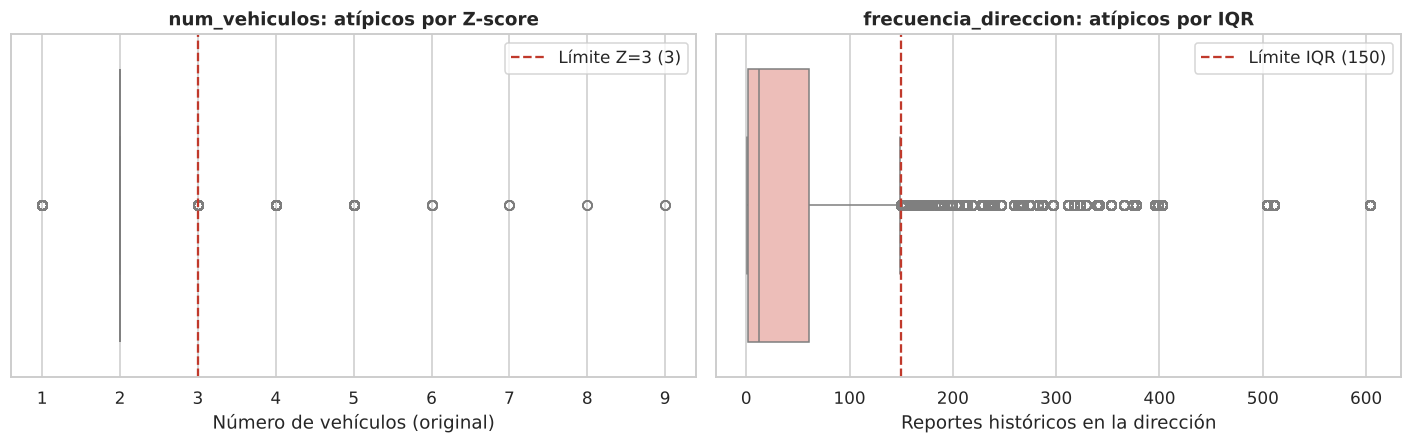

In [17]:
# 7.2 frecuencia_direccion: regla IQR sobre las direcciones con historial (train)
s = df.loc[tr & (df.frecuencia_direccion > 0), "frecuencia_direccion"]
q1, q3 = s.quantile([.25, .75]); lim = q3 + 1.5 * (q3 - q1)
n_out = (df.frecuencia_direccion > lim).sum()
print(f"frecuencia_direccion: Q1={q1}, Q3={q3}, límite superior IQR={lim:.1f}; atípicos: {n_out} ({n_out / len(df):.1%})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.boxplot(x=df["num_vehiculos_original"], ax=axes[0], color="#AED6F1")
axes[0].axvline(limite_sup, color="#C0392B", ls="--", label=f"Límite Z=3 ({limite_sup:.0f})"); axes[0].legend()
axes[0].set(title="num_vehiculos: atípicos por Z-score", xlabel="Número de vehículos (original)")
sns.boxplot(x=df.loc[df.frecuencia_direccion > 0, "frecuencia_direccion"], ax=axes[1], color="#F5B7B1")
axes[1].axvline(lim, color="#C0392B", ls="--", label=f"Límite IQR ({lim:.0f})"); axes[1].legend()
axes[1].set(title="frecuencia_direccion: atípicos por IQR", xlabel="Reportes históricos en la dirección")
fig.tight_layout(); fig.savefig(RUTA_FIG / "b01_outliers.png", bbox_inches="tight"); plt.show()

**Decisión sobre outliers:**
- `num_vehiculos`: el Z-score marca 930 siniestros (0,74 %) con 4 o más vehículos (hasta 9 en los confirmados). Son choques múltiples, **eventos reales**, no errores. Eliminarlos borraría siniestros verdaderos; dejarlos intactos distorsionaría modelos sensibles a la escala (regresión logística, KNN). Se **conservan las filas y se acota el valor** al límite de Z = 3 (winsorización). Se guarda `num_vehiculos_original` para trazabilidad.
- `frecuencia_direccion`: los atípicos por IQR (7 254 siniestros, 5,8 %, en puntos con más de 150 reportes) son las **intersecciones críticas**, justamente la información más valiosa. Se **conservan** y su sesgo se corrige con una transformación logarítmica (paso 8) en lugar de recortarlos.

## 8. Transformación de variables sesgadas

In [18]:
# log1p para frecuencia_direccion (incluye ceros) y Yeo-Johnson para num_vehiculos (ajustado en train)
df["log_frecuencia_direccion"] = np.log1p(df["frecuencia_direccion"])
pt = PowerTransformer(method="yeo-johnson", standardize=False).fit(df.loc[tr, ["num_vehiculos"]])
df["yj_num_vehiculos"] = pt.transform(df[["num_vehiculos"]]).ravel()
print(f"Lambda Yeo-Johnson (train): {pt.lambdas_[0]:.3f}")
pd.DataFrame({
    "asimetria_antes": [df.frecuencia_direccion.skew(), df.num_vehiculos_original.skew()],
    "asimetria_despues": [df.log_frecuencia_direccion.skew(), df.yj_num_vehiculos.skew()]},
    index=["frecuencia_direccion (log1p)", "num_vehiculos (acotado + Yeo-Johnson)"]).round(2)

Lambda Yeo-Johnson (train): 1.630


,asimetria_antes,asimetria_despues
frecuencia_direccion (log1p),4.41,1.30
num_vehiculos (acotado + Yeo-Johnson),1.01,0.24


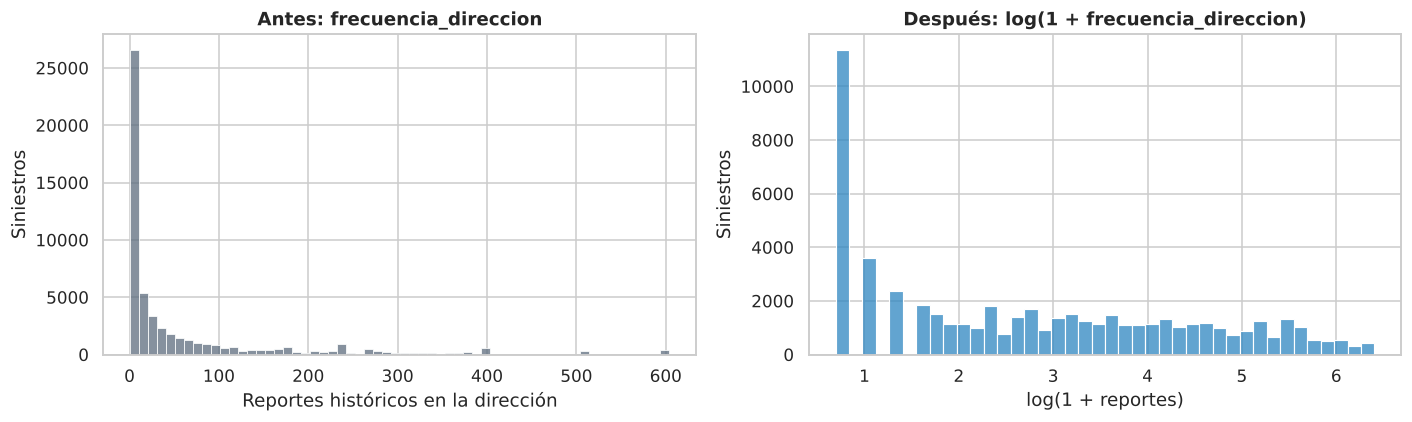

In [19]:
# Antes y después de la transformación logarítmica
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df.loc[df.frecuencia_direccion > 0, "frecuencia_direccion"], bins=60, ax=axes[0], color="#5D6D7E")
axes[0].set(title="Antes: frecuencia_direccion", xlabel="Reportes históricos en la dirección", ylabel="Siniestros")
sns.histplot(df.loc[df.frecuencia_direccion > 0, "log_frecuencia_direccion"], bins=40, ax=axes[1], color="#2E86C1")
axes[1].set(title="Después: log(1 + frecuencia_direccion)", xlabel="log(1 + reportes)", ylabel="Siniestros")
fig.tight_layout(); fig.savefig(RUTA_FIG / "b02_transformacion_log.png", bbox_inches="tight"); plt.show()

**Insight:** `frecuencia_direccion` tenía una asimetría extrema (unas pocas direcciones con cientos de reportes); con `log1p` su asimetría baja de 4,4 a 1,3, lo que favorece a modelos lineales y basados en distancias. En `num_vehiculos`, al estar concentrada en 2, ninguna transformación la vuelve normal: tras acotarla, Yeo-Johnson reduce la asimetría y se escala con RobustScaler.

## 9. Codificación de variables categóricas
- **Ordinal Encoding** para variables con **orden natural**:
  - `gravedad_p1` (variable objetivo del P1): leve < grave < mortal (codificada en el paso 4.1).
  - `vehiculo_mas_pesado`: BICICLETA < MOTO < LIVIANO < TRANSPORTE PÚBLICO < PESADO (masa e inercia creciente).
  - `franja_vehiculos`: "1" < "2" < "3+" vehículos.
- **One-Hot Encoding** (`pd.get_dummies(drop_first=True)`) para variables **nominales** sin orden: `clase_accidente`, `medio_reporte`, `tipo_via`. `drop_first=True` evita la multicolinealidad perfecta (trampa de las dummies) en la regresión logística.

In [20]:
# 9.1 Variables ordinales derivadas
def mas_pesado(r):
    """Devuelve la categoría del vehículo de mayor masa presente en el siniestro."""
    if r.n_pesados > 0: return "PESADO"
    if r.n_transporte_publico > 0: return "TRANSPORTE_PUBLICO"
    if r.n_livianos > 0: return "LIVIANO"
    if r.n_motos > 0: return "MOTO"
    if r.n_bicicletas > 0: return "BICICLETA"
    return np.nan
df["vehiculo_mas_pesado"] = df[cols_knn_obj].apply(mas_pesado, axis=1)
# Si tras KNN no hay ningún vehículo identificado se usa la MODA de train
moda_vmp = df.loc[tr, "vehiculo_mas_pesado"].mode()[0]
print("Sin vehículo identificado:", df.vehiculo_mas_pesado.isna().sum(), "-> moda train:", moda_vmp)
df["vehiculo_mas_pesado"] = df["vehiculo_mas_pesado"].fillna(moda_vmp)
df["franja_vehiculos"] = pd.cut(df["num_vehiculos"], bins=[0, 1, 2, np.inf], labels=["1", "2", "3+"]).astype(str)

orden = [["BICICLETA", "MOTO", "LIVIANO", "TRANSPORTE_PUBLICO", "PESADO"], ["1", "2", "3+"]]
enc_ord = OrdinalEncoder(categories=orden).fit(df.loc[tr, ["vehiculo_mas_pesado", "franja_vehiculos"]])
df[["ord_vehiculo_mas_pesado", "ord_franja_vehiculos"]] = enc_ord.transform(df[["vehiculo_mas_pesado", "franja_vehiculos"]])
print(df.groupby("vehiculo_mas_pesado")[["ord_vehiculo_mas_pesado", "es_grave"]].mean().sort_values("ord_vehiculo_mas_pesado").round(3))

Sin vehículo identificado: 34 -> moda train: LIVIANO
                     ord_vehiculo_mas_pesado  es_grave
vehiculo_mas_pesado                                   
BICICLETA                                0.0     0.981
MOTO                                     1.0     0.648
LIVIANO                                  2.0     0.328
TRANSPORTE_PUBLICO                       3.0     0.440
PESADO                                   4.0     0.243


**Insight:** la codificación ordinal captura una relación casi monótona con el negocio: cuando el vehículo más pesado es una bicicleta, el 98 % de los siniestros es grave; con moto, el 65 %; con liviano, el 33 %; con pesado, el 24 %. La excepción es el transporte público (44 %), porque sus siniestros suelen incluir pasajeros que caen o peatones atropellados.

In [21]:
# 9.2 One-Hot Encoding de las nominales
nominales = ["clase_accidente", "medio_reporte", "tipo_via"]
dummies = pd.get_dummies(df[nominales], prefix=["clase", "medio", "via"], drop_first=True, dtype=int)
print(f"{len(nominales)} variables nominales -> {dummies.shape[1]} columnas dummy")
print("Categorías base eliminadas (drop_first):", [sorted(df[c].unique())[0] for c in nominales])
df = pd.concat([df, dummies], axis=1)
dummies.columns.tolist()

3 variables nominales -> 20 columnas dummy
Categorías base eliminadas (drop_first): ['ATROPELLO', 'AGENTE CAD 123', 'AVENIDA']


['clase_CAIDA DE OCUPANTE',
 'clase_CHOQUE',
 'clase_NO APLICA',
 'clase_OTRO',
 'clase_SIN_DATO',
 'clase_VOLCAMIENTO',
 'medio_AGENTE RADIO',
 'medio_CAD 123',
 'medio_CAT 127',
 'medio_OTRO',
 'medio_RADIO',
 'medio_REDES SOCIALES',
 'medio_SIN_DATO',
 'medio_TELEFONICO 127',
 'via_CALLE',
 'via_CARRERA',
 'via_DIAGONAL',
 'via_OTRA_VIA',
 'via_SIN_DATO',
 'via_TRANSVERSAL']

## 10. Estandarización y normalización
Se eligen escaladores según la forma de cada variable, **ajustados solo con train**:
- **Min-Max [0, 1]**: variables acotadas y sin outliers (`mes_sin`, `mes_cos`, `dia_semana`, `anio`, `dias_desde_inicio`, ordinales).
- **Z-score (StandardScaler)**: variables aproximadamente simétricas tras la transformación (`log_frecuencia_direccion`).
- **RobustScaler** (mediana e IQR): conteos con colas largas aun después de acotar (`yj_num_vehiculos`, `n_motos`, `n_livianos`, `n_transporte_publico`, `n_pesados`, `n_bicicletas`).

El parquet guarda las variables **limpias pero sin escalar** junto con la columna `particion`; en la Fase C el mismo escalado se aplica dentro de un `Pipeline` que se ajusta solo con train. Aquí se demuestra el resultado.

In [22]:
# Grupos de escalado
ESC_MINMAX = ["mes_sin", "mes_cos", "dia_semana", "anio", "dias_desde_inicio", "ord_vehiculo_mas_pesado", "ord_franja_vehiculos"]
ESC_ZSCORE = ["log_frecuencia_direccion"]
ESC_ROBUST = ["yj_num_vehiculos"] + cols_knn_obj

escalado = {}
for nombre, cols, esc in [("minmax", ESC_MINMAX, MinMaxScaler()), ("zscore", ESC_ZSCORE, StandardScaler()),
                          ("robust", ESC_ROBUST, RobustScaler())]:
    esc.fit(df.loc[tr, cols])                               # solo train
    escalado[nombre] = pd.DataFrame(esc.transform(df[cols]), columns=cols, index=df.index)
df_escalado = pd.concat(escalado.values(), axis=1)
df_escalado[tr].describe().T[["mean", "std", "min", "50%", "max"]].round(2)

,mean,std,min,50%,max
mes_sin,0.49,0.36,0.00,0.50,1.00
mes_cos,0.51,0.35,0.00,0.50,1.00
dia_semana,0.48,0.32,0.00,0.50,1.00
anio,0.38,0.27,0.00,0.38,1.00
dias_desde_inicio,0.40,0.24,0.00,0.37,1.00
ord_vehiculo_mas_pesado,0.53,0.25,0.00,0.50,1.00
ord_franja_vehiculos,0.48,0.20,0.00,0.50,1.00
log_frecuencia_direccion,0.00,1.00,-0.68,-0.68,2.95
yj_num_vehiculos,-0.07,0.76,-1.78,0.00,2.20
n_motos,-0.39,0.61,-1.00,0.00,1.00


In [23]:
# Verificación en test: los escaladores no vieron estas filas, por eso los rangos no son exactamente [0,1] / media 0
df_escalado[~tr].describe().T[["mean", "std", "min", "max"]].round(2).head(8)

,mean,std,min,max
mes_sin,0.49,0.36,0.00,1.00
mes_cos,0.51,0.35,0.00,1.00
dia_semana,0.48,0.32,0.00,1.00
anio,0.37,0.27,0.00,1.00
dias_desde_inicio,0.40,0.24,0.00,1.00
ord_vehiculo_mas_pesado,0.53,0.25,0.00,1.00
ord_franja_vehiculos,0.47,0.20,0.00,1.00
log_frecuencia_direccion,-0.00,1.00,-0.68,2.95


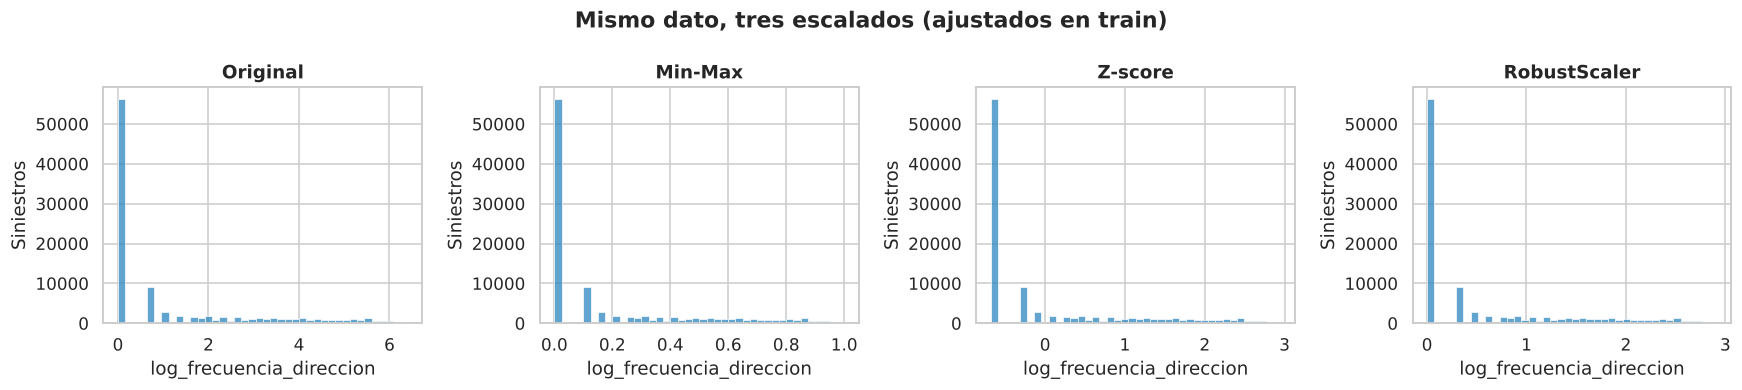

In [24]:
# Comparación visual de los tres escaladores sobre una misma variable
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
v = df.loc[tr, "log_frecuencia_direccion"].to_frame()
for ax, (titulo, datos) in zip(axes, [("Original", v.values.ravel()),
                                      ("Min-Max", MinMaxScaler().fit_transform(v).ravel()),
                                      ("Z-score", StandardScaler().fit_transform(v).ravel()),
                                      ("RobustScaler", RobustScaler().fit_transform(v).ravel())]):
    sns.histplot(datos, bins=40, ax=ax, color="#2E86C1"); ax.set(title=titulo, xlabel="log_frecuencia_direccion", ylabel="Siniestros")
fig.suptitle("Mismo dato, tres escalados (ajustados en train)", fontweight="bold"); fig.tight_layout()
fig.savefig(RUTA_FIG / "b03_escaladores.png", bbox_inches="tight"); plt.show()

## 11. DataFrame final y guardado

In [25]:
# Selección de columnas finales: identificación, objetivo, partición y variables modelables
FEATURES = (["anio", "mes", "dia_semana", "es_fin_de_semana", "periodo_covid", "dias_desde_inicio", "mes_sin", "mes_cos",
             "num_vehiculos", "yj_num_vehiculos"] + cols_knn_obj +
            ["vehiculos_sin_dato", "tiene_direccion", "es_clinica", "es_interseccion",
             "frecuencia_direccion", "log_frecuencia_direccion",
             "ord_vehiculo_mas_pesado", "ord_franja_vehiculos"] + dummies.columns.tolist())
df_limpio = df[["codigo", "fecha", "tipo_confirmado", "direccion_norm", "vehiculo_mas_pesado",
                "clase_accidente", "medio_reporte", "es_grave", "gravedad_p1", "ord_gravedad_p1", "particion"] + FEATURES].reset_index(drop=True)
df_limpio["codigo"] = df_limpio["codigo"].astype(str).str.strip()
print("Forma final:", df_limpio.shape, "| nulos totales:", int(df_limpio[FEATURES].isna().sum().sum()))
df_limpio.to_parquet("datos_limpios.parquet", index=False)
print("Guardado: entrega/datos_limpios.parquet")
df_limpio.head()

Forma final: (124889, 54) | nulos totales: 0


Guardado: entrega/datos_limpios.parquet


,codigo,fecha,tipo_confirmado,direccion_norm,vehiculo_mas_pesado,clase_accidente,medio_reporte,es_grave,gravedad_p1,ord_gravedad_p1,...,medio_RADIO,medio_REDES SOCIALES,medio_SIN_DATO,medio_TELEFONICO 127,via_CALLE,via_CARRERA,via_DIAGONAL,via_OTRA_VIA,via_SIN_DATO,via_TRANSVERSAL
0,96159,2016-01-01,SOLO DANOS,CARRERA 56 CON CALLE 1 A,MOTO,SIN_DATO,RADIO,0,leve,0,...,1,0,0,0,0,1,0,0,0,0
1,96161,2016-01-01,CON LESIONADO,CARRERA 94 CON CALLE 4 C,MOTO,ATROPELLO,TELEFONICO 127,1,grave,1,...,0,0,0,1,0,1,0,0,0,0
2,96162,2016-01-01,CON LESIONADO,CARRERA 8 A CON CALLE 44,MOTO,VOLCAMIENTO,RADIO,1,grave,1,...,1,0,0,0,0,1,0,0,0,0
3,96164,2016-01-01,SOLO DANOS,CARRERA 46 C CON CALLE 36,LIVIANO,SIN_DATO,RADIO,0,leve,0,...,1,0,0,0,0,1,0,0,0,0
4,96167,2016-01-01,CON LESIONADO,CARRERA 23 CON TRANSVERSAL 25,MOTO,SIN_DATO,CAD 123,1,grave,1,...,0,0,0,0,0,1,0,0,0,0


In [26]:
# Verificación: lectura del parquet y tipos de datos
verif = pd.read_parquet("datos_limpios.parquet")
assert verif.shape == df_limpio.shape and verif[FEATURES].isna().sum().sum() == 0
verif.dtypes.value_counts()

int64             29
float64           13
str                8
int32              3
datetime64[us]     1
Name: count, dtype: int64

## Resumen de decisiones
| Paso | Decisión | Por qué |
|---|---|---|
| Duplicados | 4 filas idénticas + 1 vacía eliminadas | Contarían dos veces el mismo siniestro |
| Alcance | Solo siniestros confirmados (124 889) | Los reportes negativos no tienen gravedad |
| Fuga | Se elimina `detalle_confirmado` | Se escribe después de conocer la gravedad |
| Texto | Mayúsculas, sin tildes, sinónimos unificados, raras → OTRO | Una categoría = una columna |
| Nulos | Mediana, KNN, moda, categoría `SIN_DATO`, indicadores | Según tipo y mecanismo del faltante |
| Outliers | Z-score (num_vehiculos, 0,74 %) → acotar a 3; IQR (frecuencia, 5,8 %) → conservar + log | Son eventos reales |
| Transformaciones | log1p, Yeo-Johnson, mes cíclico | Reducir sesgo y respetar ciclos |
| Encoding | Ordinal (2 variables), One-Hot `drop_first=True` (3 variables) | Orden natural vs nominal |
| Escalado | Min-Max, Z-score, Robust; ajustados en train | Según forma de la variable; sin fuga |
| Continuidad P1 | Objetivo `gravedad_p1` (leve/grave/mortal, ordinal 0-1-2), regla "Desconocido" → `SIN_DATO`, validaciones de la sección 7 resueltas | Mantener el caso de negocio y las reglas de la bodega del Proyecto 1 |